<a href="https://colab.research.google.com/github/njalagam23/neural-networks-from-scratch/blob/main/day03_pytorch_customer_churn_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

rng = np.random.default_rng(42)

# Generate 400 synthetic customers
n = 400

usage = rng.uniform(0, 40, n)
tenure = rng.integers(1, 61, n)
tickets = rng.poisson(1.5, n)

X = np.column_stack([usage, tenure, tickets])

# Simulated churn outcomes
logits = 0.9 - 0.14 * usage - 0.035 * tenure + 0.9 * tickets
true_probs = 1 / (1 + np.exp(-logits))

y = (rng.random(n) < true_probs).astype(float).reshape(-1, 1)

# Train/test split
idx = rng.permutation(n)
train_idx, test_idx = idx[:320], idx[320:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Standardize using training statistics only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (320, 3)
Testing: (80, 3)


In [3]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(X_train_t.shape)
print(X_test_t.shape)
print(y_train_t.shape)
print(y_test_t.shape)

torch.Size([320, 3])
torch.Size([80, 3])
torch.Size([320, 1])
torch.Size([80, 1])


In [4]:
model = nn.Sequential(
    nn.Linear(3, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

print(model)

Sequential(
  (0): Linear(in_features=3, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)


In [5]:
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.2
)

In [6]:
epochs = 600

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    logits = model(X_train_t)

    # Calculate loss
    loss = loss_fn(logits, y_train_t)

    # Clear old gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch+1}, "
            f"Loss: {loss.item():.4f}"
        )

Epoch 100, Loss: 0.3436
Epoch 200, Loss: 0.3386
Epoch 300, Loss: 0.3366
Epoch 400, Loss: 0.3350
Epoch 500, Loss: 0.3333
Epoch 600, Loss: 0.3314


In [7]:
for name, parameter in model.named_parameters():
    print(name)
    print("Parameter shape:", parameter.shape)
    print("Gradient shape:", parameter.grad.shape)
    print()

0.weight
Parameter shape: torch.Size([8, 3])
Gradient shape: torch.Size([8, 3])

0.bias
Parameter shape: torch.Size([8])
Gradient shape: torch.Size([8])

2.weight
Parameter shape: torch.Size([1, 8])
Gradient shape: torch.Size([1, 8])

2.bias
Parameter shape: torch.Size([1])
Gradient shape: torch.Size([1])



In [8]:
model.eval()

with torch.no_grad():

    logits = model(X_test_t)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).float()

    accuracy = (
        (predictions == y_test_t)
        .float()
        .mean()
        .item()
    )

    test_loss = loss_fn(logits, y_test_t).item()

baseline = max(
    y_test_t.mean().item(),
    1 - y_test_t.mean().item()
)

print("Test Accuracy:", accuracy)
print("Test Loss:", test_loss)
print("Majority-Class Baseline:", baseline)

Test Accuracy: 0.7875000238418579
Test Loss: 0.40147432684898376
Majority-Class Baseline: 0.6500000059604645


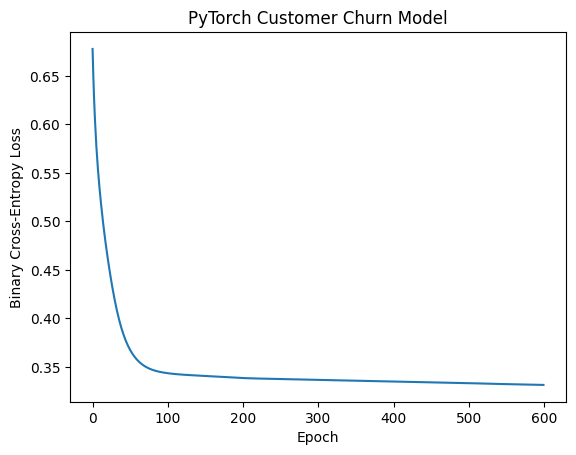

In [9]:
plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("PyTorch Customer Churn Model")

plt.show()